1. Importa las librerías necesarias para entrenar modelos de regresión logística con
validación cruzada y Extreme Gradient Boosting, carga los datos y prepáralos. Para
ello:
a. elimina la columna ‘Unnamed: 0’.
b. codifica la variable objetivo Category en dos categorías: una para
Category=’0=Blood Donor’, a la que debes asociar valor 0, y un 1 para los
demás valores. Asigna estos valores en una nueva columna llamada target.
c. codifica en otra columna, con nombre suspect, con valor 1 cuando
Category=’0s=suspect Blood Donor’, y aigna 0 en caso contrario. Elimina
finalmente la columna Category.
d. Revisa si la base de datos contiene valores ausentes. En caso que sea así,
aplica los siguientes criterios:
i. si el porcentaje de valores ausentes para alguna variable es menor a
1%, entonces elimina las filas que contengan estos valores ausentes
ii. si el porcentaje de valores ausentes es mayor, entonces reemplaza
estos por el promedio según la clase a la que pertenezca el valor
ausente.
e. Realiza un análisis descriptivo para cada variable regresora, usando gráficos
para representar distribuciones y boxplot para revisar posibles outliers.
Construye un heatmap que muestre las correlaciones entre las variables
regresoras y describe.
f. Transforma las variables regresoras por medio de la estandarización.
Muestra el antes y después de esta usando boxplots, y realiza una
segmentación de la muestra en 33% para test y el resto para entrenamien

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import classification_report, f1_score
from xgboost import XGBClassifier

plt.style.use('seaborn-v0_8-whitegrid')
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.0


In [2]:
df = pd.read_csv('hcvdat0.csv')
print('Dimensión original:', df.shape)
print(df['Category'].value_counts())

df = df.drop(columns=['Unnamed: 0'])

df['target'] = (df['Category'] != '0=Blood Donor').astype(int)
df['suspect'] = (df['Category'] == '0s=suspect Blood Donor').astype(int)

print('\nCategory vs target:')
print(pd.crosstab(df['Category'], df['target']))
print('\nsuspect vs target:')
print(pd.crosstab(df['suspect'], df['target']))

df = df.drop(columns=['Category'])
print('\nDimensión tras la codificación:', df.shape)
df.head()

Dimensión original: (615, 14)
Category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: count, dtype: int64

Category vs target:
target                    0   1
Category                       
0=Blood Donor           533   0
0s=suspect Blood Donor    0   7
1=Hepatitis               0  24
2=Fibrosis                0  21
3=Cirrhosis               0  30

suspect vs target:
target     0   1
suspect         
0        533  75
1          0   7

Dimensión tras la codificación: (615, 14)


,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


In [3]:
ausentes = pd.DataFrame({
    'n_ausentes': df.isna().sum(),
    'pct_ausentes': (df.isna().mean() * 100).round(2)
})
print(ausentes[ausentes['n_ausentes'] > 0].sort_values('pct_ausentes', ascending=False))

cols_menor_1 = ausentes[(ausentes['pct_ausentes'] > 0) & (ausentes['pct_ausentes'] < 1)].index.tolist()
cols_mayor_1 = ausentes[ausentes['pct_ausentes'] >= 1].index.tolist()
print('\nSe eliminan filas con ausentes en:', cols_menor_1)
print('Se imputan por clase:', cols_mayor_1)

print('\nAusentes por clase en las columnas a imputar:')
print(df.groupby('target')[cols_mayor_1].apply(lambda g: g.isna().sum()))

df = df.dropna(subset=cols_menor_1)
print('\nDimensión tras eliminar filas:', df.shape)

valores_imputacion = df.groupby('target')[cols_mayor_1].mean()
print('\nValores de imputación por clase:')
print(valores_imputacion.round(2))

for col in cols_mayor_1:
    df[col] = df[col].fillna(df['target'].map(valores_imputacion[col]))

print('\nAusentes restantes:', df.isna().sum().sum())
print('Distribución de target:', df['target'].value_counts().to_dict())

      n_ausentes  pct_ausentes
ALP           18          2.93
CHOL          10          1.63
ALB            1          0.16
ALT            1          0.16
PROT           1          0.16

Se eliminan filas con ausentes en: ['ALB', 'ALT', 'PROT']
Se imputan por clase: ['ALP', 'CHOL']

Ausentes por clase en las columnas a imputar:
        ALP  CHOL
target           
0         0     7
1        18     3

Dimensión tras eliminar filas: (612, 14)

Valores de imputación por clase:
          ALP  CHOL
target             
0       68.37  5.49
1       67.79  4.51

Ausentes restantes: 0
Distribución de target: {0: 533, 1: 79}


In [4]:
df['Sex'] = (df['Sex'] == 'm').astype(int)

regresoras = [c for c in df.columns if c not in ['target', 'suspect']]
continuas = [c for c in regresoras if c != 'Sex']

print('Variables regresoras:', regresoras)
print('Sex (0=f, 1=m):', df['Sex'].value_counts().to_dict())

Variables regresoras: ['Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
Sex (0=f, 1=m): {1: 374, 0: 238}


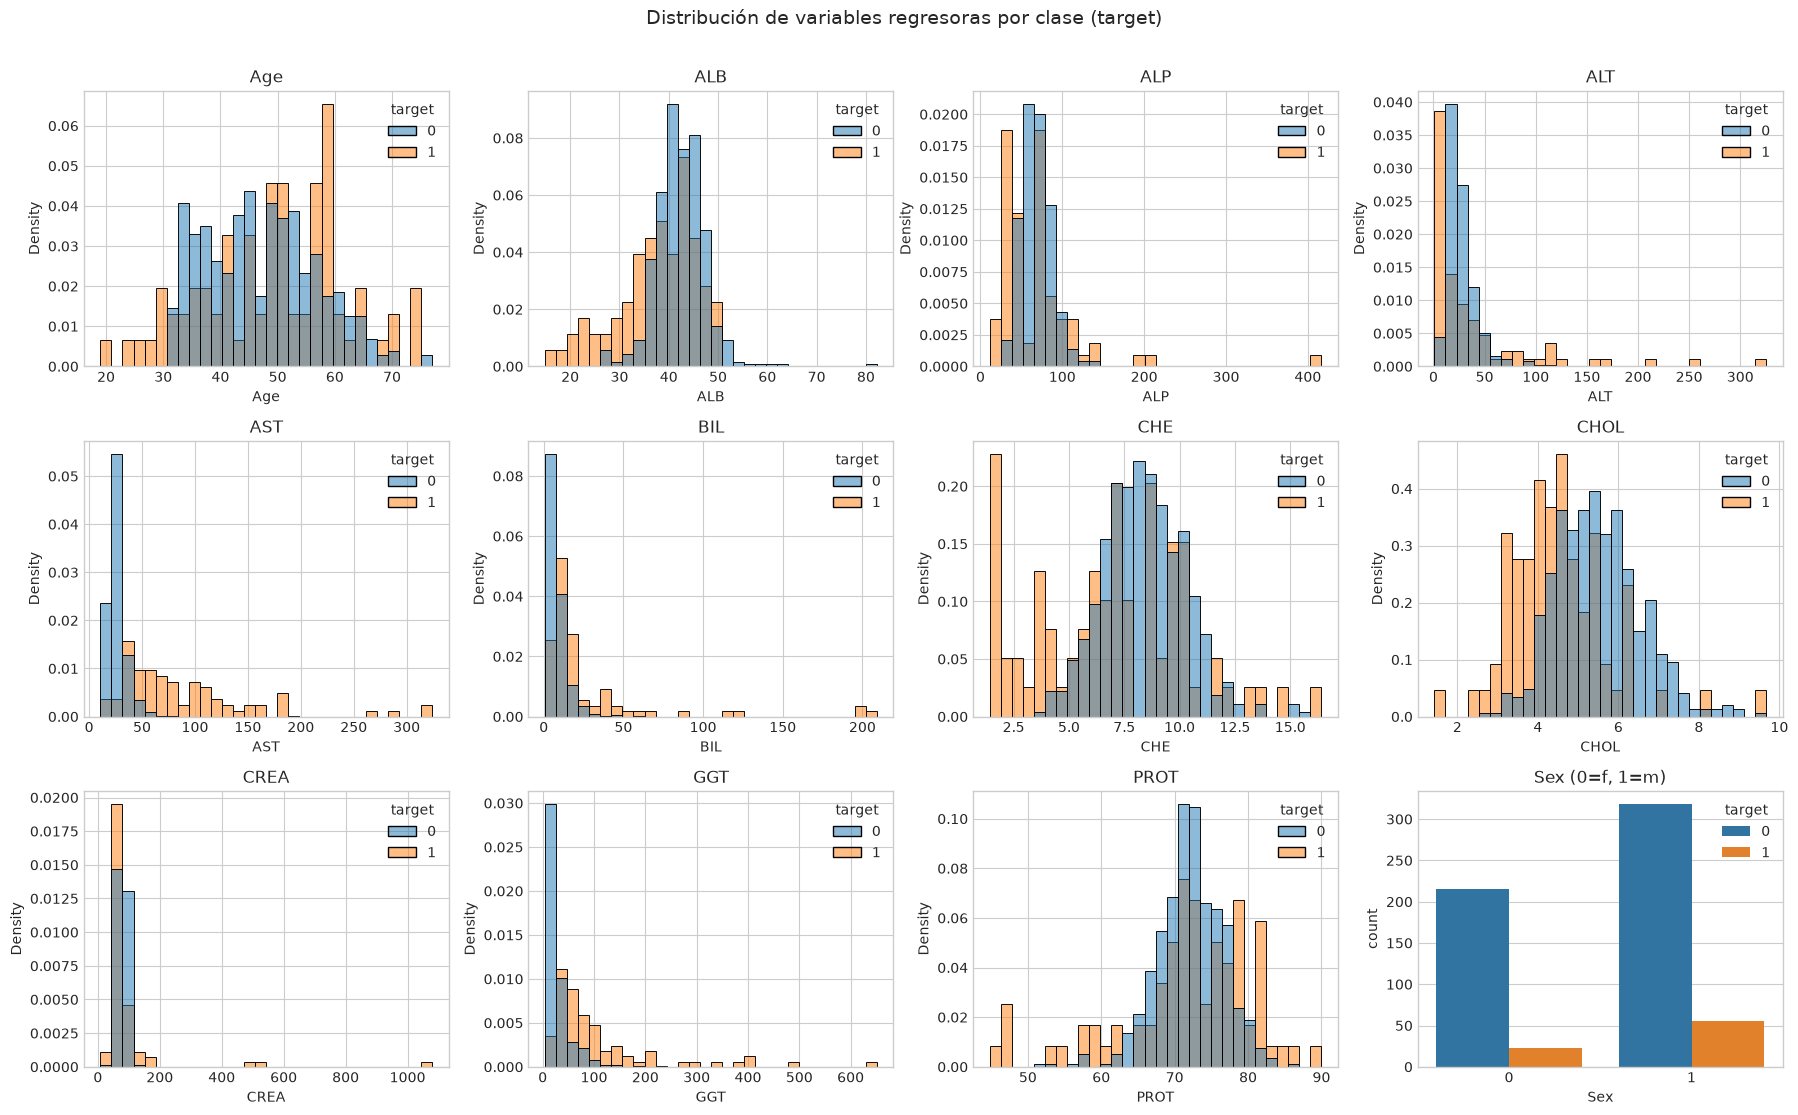

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for ax, col in zip(axes.flat, continuas):
    sns.histplot(data=df, x=col, hue='target', stat='density',
                 common_norm=False, bins=30, ax=ax)
    ax.set_title(col)

sns.countplot(data=df, x='Sex', hue='target', ax=axes.flat[-1])
axes.flat[-1].set_title('Sex (0=f, 1=m)')

plt.suptitle('Distribución de variables regresoras por clase (target)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

**Observaciones de las distribuciones:** las variables que más diferencian a los pacientes con condición de los donantes sanos son las enzimas y marcadores hepáticos: AST (mediana 68.9 vs 24.8), GGT (68.2 vs 21.4) y BIL (14.0 vs 6.9) son mucho más altos en enfermos, mientras que CHE (7.1 vs 8.4), ALB (39.0 vs 42.2) y CHOL (4.3 vs 5.4) son más bajos, coherente con una menor función hepática. ALT muestra un comportamiento mixto: mediana menor en enfermos pero con una cola de valores muy altos, posiblemente por la mezcla de diagnósticos (hepatitis vs cirrosis). ALP, PROT y CREA tienen medianas similares entre clases, aunque los enfermos presentan mayor dispersión. Los enfermos son levemente mayores y la condición es más frecuente en hombres (15% vs 9.7%). ALP, ALT, AST, BIL, CREA y GGT presentan fuerte asimetría positiva.

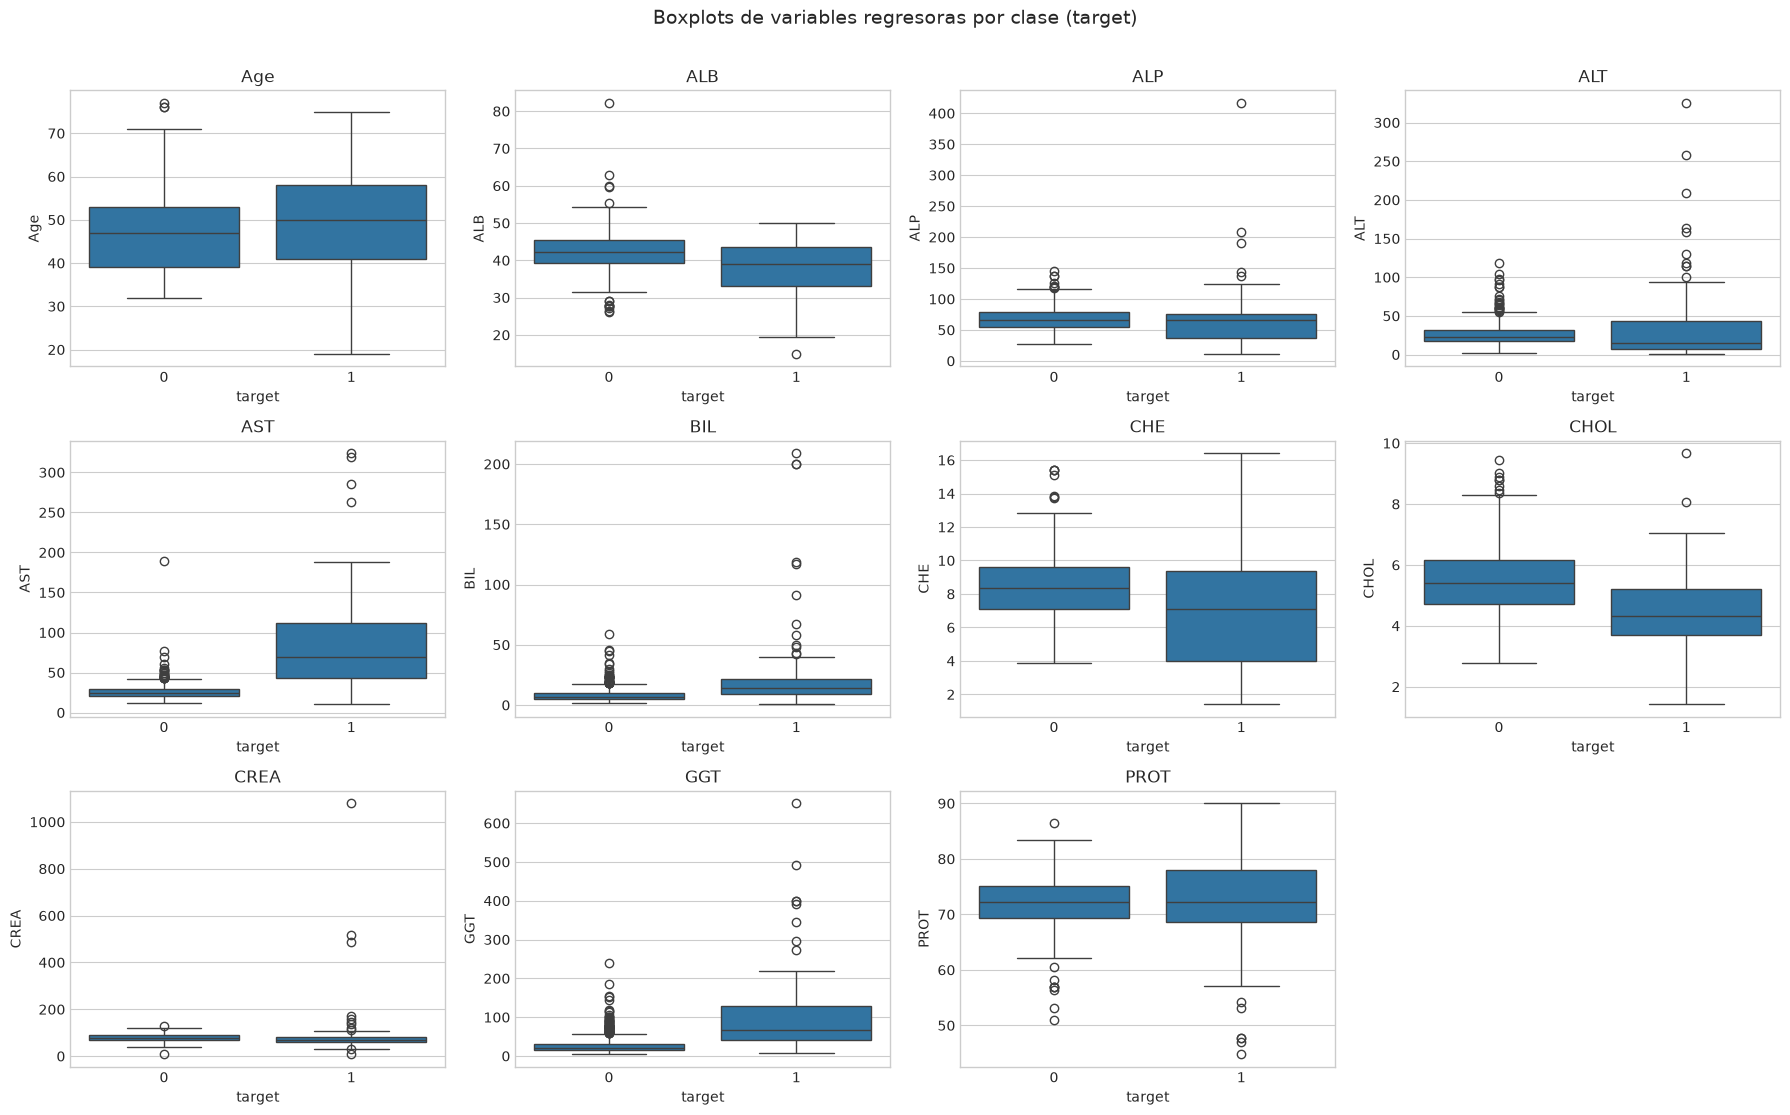

,n_outliers,pct_outliers,pct_de_outliers_en_clase_1
GGT,65,10.6,52.0
AST,62,10.1,84.0
BIL,46,7.5,50.0
ALT,35,5.7,46.0
ALB,26,4.2,50.0
CHE,23,3.8,70.0
PROT,20,3.3,60.0
ALP,13,2.1,54.0
CREA,12,2.0,83.0
CHOL,12,2.0,25.0


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for ax, col in zip(axes.flat, continuas):
    sns.boxplot(data=df, x='target', y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')

plt.suptitle('Boxplots de variables regresoras por clase (target)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

q1 = df[continuas].quantile(0.25)
q3 = df[continuas].quantile(0.75)
iqr = q3 - q1
es_outlier = (df[continuas] < q1 - 1.5 * iqr) | (df[continuas] > q3 + 1.5 * iqr)

tabla_outliers = pd.DataFrame({
    'n_outliers': es_outlier.sum(),
    'pct_outliers': (es_outlier.mean() * 100).round(1),
    'pct_de_outliers_en_clase_1': (es_outlier[df['target'] == 1].sum() / es_outlier.sum() * 100).round(0)
})
tabla_outliers.sort_values('n_outliers', ascending=False)

**Observaciones de los boxplots y outliers:** las variables hepáticas presentan numerosos outliers según el criterio de 1.5 IQR (GGT 10.6%, AST 10.1%, BIL 7.5%, ALT 5.7%). Aunque los pacientes con condición son solo el 12.9% de la muestra, representan entre el 46% y el 84% de los outliers (84% en AST, 83% en CREA, 70% en CHE). Por lo tanto, los valores extremos no son errores de medición sino manifestaciones de la enfermedad, y **no se eliminan**: hacerlo removería los casos más informativos de la clase minoritaria. En AST y GGT la caja de la clase 1 se ubica casi completamente sobre la de la clase 0, lo que anticipa su alto poder predictivo. Como consideración, la estandarización no corrige la asimetría de estas variables; una transformación logarítmica podría beneficiar al modelo lineal, aunque no se aplica para seguir lo solicitado. Los modelos de árboles (XGBoost) no son sensibles a estos valores extremos.

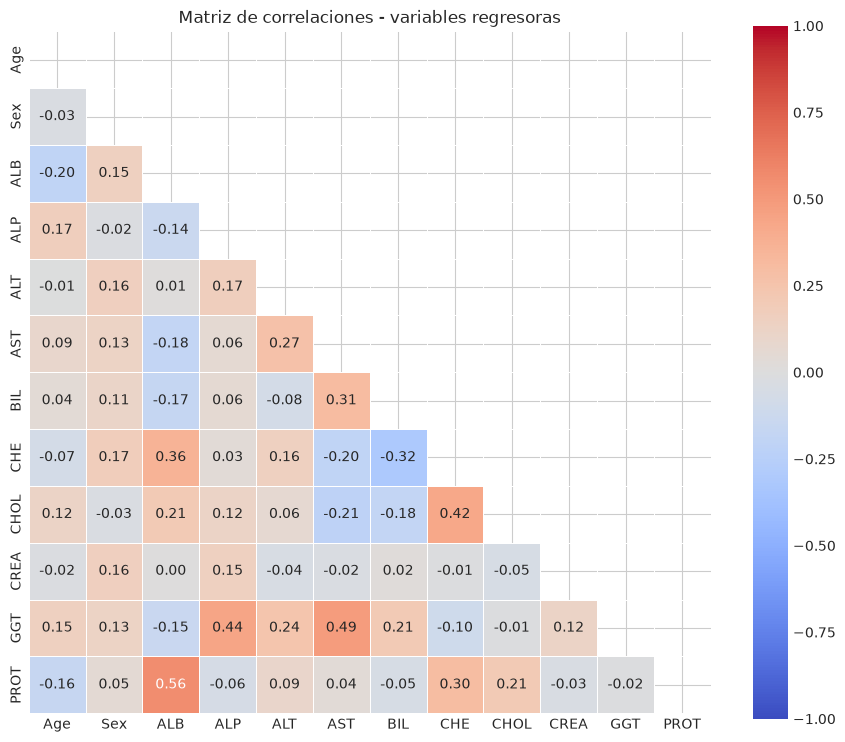

Correlación de cada regresora con target:
AST     0.64
GGT     0.49
BIL     0.38
CHOL   -0.29
ALB    -0.27
CHE    -0.23
ALT     0.18
CREA    0.12
Sex     0.08
Age     0.07
PROT   -0.03
ALP    -0.01
Name: target, dtype: float64


In [7]:
corr = df[regresoras].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Matriz de correlaciones - variables regresoras')
plt.show()

print('Correlación de cada regresora con target:')
print(df[regresoras + ['target']].corr()['target'].drop('target')
      .sort_values(key=abs, ascending=False).round(2))

**Observaciones del heatmap:** la correlación más alta entre regresoras es ALB–PROT (0.56), esperable porque la albúmina forma parte de las proteínas totales. Le siguen AST–GGT (0.49) y ALP–GGT (0.44), enzimas que se elevan conjuntamente ante daño hepático, y CHE–CHOL (0.42) y ALB–CHE (0.36), marcadores de la función de síntesis del hígado. BIL se correlaciona negativamente con CHE (−0.32). Ninguna correlación supera 0.6, por lo que no hay multicolinealidad severa; aun así, la componente L2 de Elastic Net contribuye a estabilizar los coeficientes de variables correlacionadas. Age, Sex y CREA se relacionan débilmente con el resto.

**Correlación con target:** AST (+0.64), GGT (+0.49) y BIL (+0.38) son las más asociadas positivamente con la condición, y CHOL (−0.29), ALB (−0.27) y CHE (−0.23) negativamente. Son candidatas a tener mayor peso en los modelos.

Train: (410, 12) | Test: (202, 12)
Proporción de clase 1 -> train: 0.129 | test: 0.129


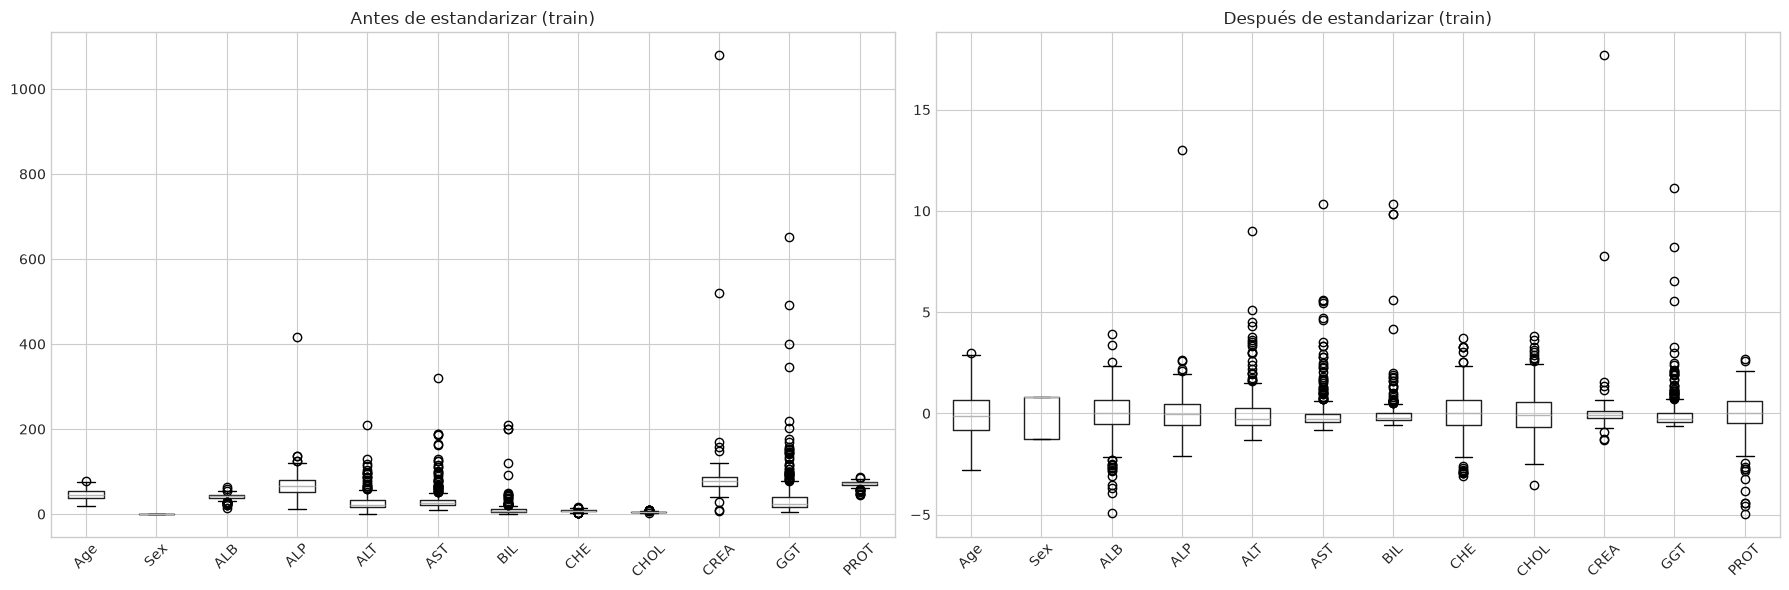

      Age  Sex  ALB  ALP  ALT  AST  BIL  CHE  CHOL  CREA  GGT  PROT
mean -0.0  0.0  0.0  0.0 -0.0 -0.0  0.0  0.0   0.0  -0.0  0.0   0.0
std   1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0   1.0   1.0  1.0   1.0


In [8]:
X = df[regresoras]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train),
                           columns=regresoras, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test),
                          columns=regresoras, index=X_test.index)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporción de clase 1 -> train:', round(y_train.mean(), 3),
      '| test:', round(y_test.mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
X_train.boxplot(ax=axes[0], rot=45)
axes[0].set_title('Antes de estandarizar (train)')
X_train_std.boxplot(ax=axes[1], rot=45)
axes[1].set_title('Después de estandarizar (train)')
plt.tight_layout()
plt.show()

print(X_train_std.describe().loc[['mean', 'std']].round(2))

**Observaciones de la estandarización:** antes de transformar, las variables tienen escalas muy distintas (CREA llega a ~1.080 y GGT a ~650, mientras CHE o CHOL se mueven en unidades), lo que impide compararlas y haría que la regularización penalizara los coeficientes de forma desigual por razones de unidad de medida. Tras la estandarización (ajustada solo con el conjunto de entrenamiento para evitar fuga de información hacia el test), todas quedan centradas en 0 con desviación 1. Los outliers se conservan: la estandarización modifica la escala pero no la forma de las distribuciones, y algunos pacientes quedan a más de 10 desviaciones de la media (CREA ~17.7, ALP ~13).

### Conclusión del paso 1
Se trabaja con 612 pacientes (533 sanos y 79 con condición, 12.9%) y 12 variables regresoras. `suspect` se excluye por ser derivada de la variable objetivo. Las variables con mayor poder discriminante son AST, GGT y BIL (más altas en enfermos) y CHOL, ALB y CHE (más bajas). Los outliers corresponden mayoritariamente a pacientes enfermos y se conservan. No hay multicolinealidad severa. La muestra se dividió de forma estratificada (410 entrenamiento / 202 test) y se estandarizó con los parámetros del entrenamiento.

2. Desarrolla un modelo regresión logística con validación cruzada usando 5-fold, con
regularización Elastic Net. Busca para los siguientes hiper parámetros:
● Cs: valores entre 0.01 y 5.0, con 200 valores lineales.
● l1_ratio: valores entre 0 y 1, con 200 valores lineales.
Muestra los valores óptimos encontrados, y las métricas precisión, recall, f1-score y
accuracy. Describe cuáles son las tres características con mayor incidencia en la
predicción de sujeto o muestra con sangre con posible enfermedad.



In [19]:
import time

valores_Cs = np.linspace(0.01, 5.0, 200)
valores_l1 = np.linspace(0, 1, 200)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

inicio = time.time()
logit_en = LogisticRegressionCV(
    Cs=valores_Cs,
    l1_ratios=valores_l1,
    solver='saga',
    cv=cv5,
    scoring='f1',
    max_iter=5000,
    random_state=42,
    n_jobs=-1,
    use_legacy_attributes=False
)
logit_en.fit(X_train_std, y_train)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

print(f'C óptimo: {logit_en.C_:.4f}  (λ equivalente = 1/C = {1 / logit_en.C_:.4f})')
print(f'l1_ratio óptimo: {logit_en.l1_ratio_:.4f}')
print(f'Mejor F1 promedio en validación cruzada: {logit_en.scores_.mean(axis=0).max():.4f}')

Tiempo de búsqueda: 11.1 minutos
C óptimo: 3.3199  (λ equivalente = 1/C = 0.3012)
l1_ratio óptimo: 0.0000
Mejor F1 promedio en validación cruzada: 0.7813


**Observación hiperparámetros óptimos:** la validación cruzada seleccionó l1_ratio = 0 (regularización Ridge pura) y C = 3.32 (λ = 1/C ≈ 0.30), con F1 promedio de 0.781 en los 5 folds. Que la mezcla óptima sea Ridge indica que conviene conservar todas las variables reduciendo la magnitud de sus coeficientes, en lugar de descartar algunas (Lasso): casi todas aportan información y existen pares correlacionados (ALB–PROT, AST–GGT, ALP–GGT), donde Ridge reparte el peso en vez de anular una de las variables. El valor de C, en la parte alta del rango, indica una regularización suave: con 12 variables y 410 observaciones, el modelo lineal tiene poca tendencia al sobreajuste. El óptimo no se ubica en el límite de la grilla.

In [ ]:
from sklearn.metrics import confusion_matrix

yhat_train_en = logit_en.predict(X_train_std)
yhat_test_en = logit_en.predict(X_test_std)

print('Métricas en train:')
print(classification_report(y_train, yhat_train_en, digits=3))
print('Métricas en test:')
print(classification_report(y_test, yhat_test_en, digits=3))

print('Matriz de confusión en test (filas = real, columnas = predicho):')
print(pd.DataFrame(confusion_matrix(y_test, yhat_test_en),
                   index=['Real 0 (sano)', 'Real 1 (condición)'],
                   columns=['Pred 0', 'Pred 1']))

Métricas en train:
              precision    recall  f1-score   support

           0      0.965     0.992     0.978       357
           1      0.930     0.755     0.833        53

    accuracy                          0.961       410
   macro avg      0.947     0.873     0.906       410
weighted avg      0.960     0.961     0.959       410

Métricas en test:
              precision    recall  f1-score   support

           0      0.946     0.994     0.970       176
           1      0.941     0.615     0.744        26

    accuracy                          0.946       202
   macro avg      0.944     0.805     0.857       202
weighted avg      0.945     0.946     0.941       202

Matriz de confusión en test (filas = real, columnas = predicho):
                    Pred 0  Pred 1
Real 0 (sano)          175       1
Real 1 (condición)      10      16


**Observación métricas Elastic Net:** el modelo alcanza un accuracy de 94.6% en test, pero esta métrica es engañosa por el desbalance de clases (un modelo que prediga siempre "sano" obtendría 87.1%). En la clase 1, la precision es alta (0.941: un solo falso positivo entre 176 sanos), pero el recall es bajo (0.615): detecta 16 de 26 pacientes con condición y deja 10 sin detectar. El modelo es conservador: solo predice "condición" cuando la probabilidad es alta. El F1 de la clase 1 baja de 0.833 en train a 0.744 en test (0.781 en validación cruzada), un sobreajuste moderado, aunque con solo 26 casos positivos en test cada paciente mal clasificado modifica el recall en casi 4 puntos. Para un uso clínico de tamizaje, donde los falsos negativos son el error más costoso, convendría ponderar las clases (`class_weight='balanced'`) o reducir el umbral de decisión.

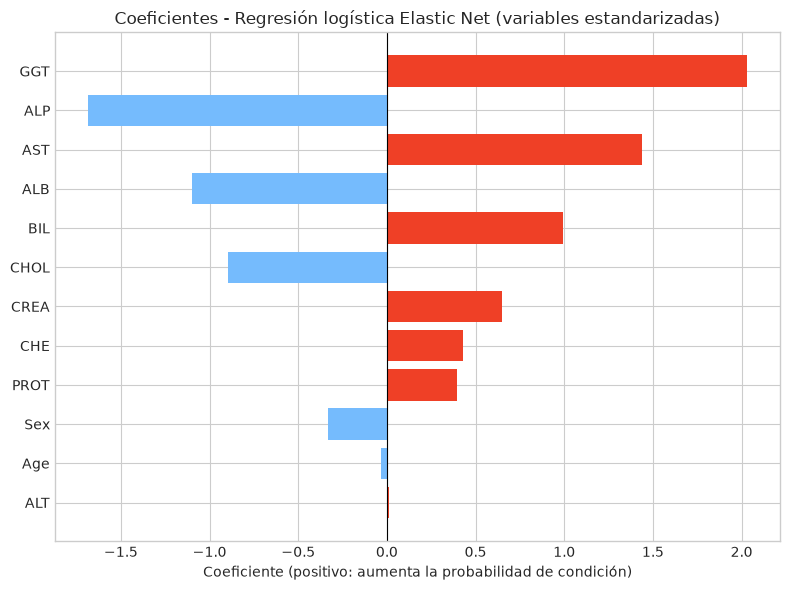

,coeficiente,odds_ratio
GGT,2.031,7.619
ALP,-1.686,0.185
AST,1.441,4.225
ALB,-1.101,0.333
BIL,0.995,2.704
CHOL,-0.895,0.409
CREA,0.648,1.912
CHE,0.429,1.536
PROT,0.395,1.484
Sex,-0.334,0.716


In [ ]:
coeficientes = pd.Series(logit_en.coef_[0], index=regresoras)
orden = coeficientes.abs().sort_values()

colores = ['xkcd:tomato' if c > 0 else 'xkcd:sky blue' for c in coeficientes[orden.index]]
plt.figure(figsize=(8, 6))
plt.barh(orden.index, coeficientes[orden.index], color=colores)
plt.axvline(0, color='black', lw=0.8)
plt.title('Coeficientes - Regresión logística Elastic Net (variables estandarizadas)')
plt.xlabel('Coeficiente (positivo: aumenta la probabilidad de condición)')
plt.tight_layout()
plt.show()

tabla_coef = pd.DataFrame({
    'coeficiente': coeficientes,
    'odds_ratio': np.exp(coeficientes)
}).loc[orden.index[::-1]].round(3)
tabla_coef

### Variables con mayor incidencia en la predicción

Como las variables están estandarizadas, los coeficientes son comparables y su valor absoluto mide la incidencia de cada una. Las tres más influyentes son:

1. **GGT (coef. +2.02, odds ratio ≈ 7.5):** cada desviación estándar adicional multiplica por ~7.5 las chances de presentar una condición hepática.
2. **ALP (coef. −1.67, odds ratio ≈ 0.19):** valores bajos de ALP se asocian a mayor probabilidad de condición. Aunque su correlación simple con target es casi nula (−0.01), el modelo la usa en conjunto con GGT (correlación 0.44): entre pacientes con igual GGT, una ALP menor indica mayor riesgo.
3. **AST (coef. +1.45, odds ratio ≈ 4.3):** consistente con su alta correlación con target (+0.64) y la clara separación observada en los boxplots.

Les siguen ALB (−1.09) y CHOL (−0.89), marcadores de función hepática más bajos en enfermos, y BIL (+0.96). ALT y Age quedan con coeficientes cercanos a cero: Ridge reduce su influencia sin eliminarlas. Algunos signos (CHE positivo, Sex negativo) se explican porque cada coeficiente mide el efecto de su variable manteniendo constantes las demás, y con variables correlacionadas el peso se redistribuye. Los coeficientes deben interpretarse como asociaciones dentro del modelo y no como relaciones causales.

3. Implementa un modelo Extreme Gradient Boosting con búsqueda de hiper
parámetros de grilla, con regularización para la combinación L1 y L2. Considera para
esto:
a. reg_lambda: valores entre 0.0 y 2.0, con 10 valores lineales.
b. reg_alpha: valores entre 0 y 1, con 10 valores lineales.
c. learning_rate: valores entre 0.1 a 10, con 20 valores lineales.

In [14]:
grilla_xgb = {
    'reg_lambda': np.linspace(0.0, 2.0, 10),
    'reg_alpha': np.linspace(0, 1, 10),
    'learning_rate': np.linspace(0.1, 10, 20)
}

inicio = time.time()
xgb_grid = GridSearchCV(
    XGBClassifier(random_state=42, n_jobs=1),
    param_grid=grilla_xgb,
    scoring='f1',
    cv=cv5,
    n_jobs=1,
    verbose=1
)
xgb_grid.fit(X_train_std, y_train)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

print('Mejores hiperparámetros:', xgb_grid.best_params_)
print(f'Mejor F1 promedio en validación cruzada: {xgb_grid.best_score_:.4f}')

Fitting 5 folds for each of 2000 candidates, totalling 10000 fits
Tiempo de búsqueda: 2.7 minutos
Mejores hiperparámetros: {'learning_rate': np.float64(0.6210526315789474), 'reg_alpha': np.float64(0.1111111111111111), 'reg_lambda': np.float64(1.1111111111111112)}
Mejor F1 promedio en validación cruzada: 0.8816


**Observación hiperparámetros óptimos XGBoost:** learning_rate = 0.62, reg_alpha (L1) = 0.11 y reg_lambda (L2) = 1.11, con F1 promedio de 0.882 en validación cruzada (vs 0.781 de la regresión logística con Elastic Net, sobre los mismos folds). La regularización seleccionada es suave y combina ambas normas: un L1 leve y un L2 cercano al valor por defecto de XGBoost. El learning_rate óptimo corresponde al segundo valor más bajo de la grilla. La mejora sobre la regresión logística es consistente con la presencia de relaciones no lineales en los datos (por ejemplo, ALT y ALP), que los árboles pueden capturar y un modelo lineal no.

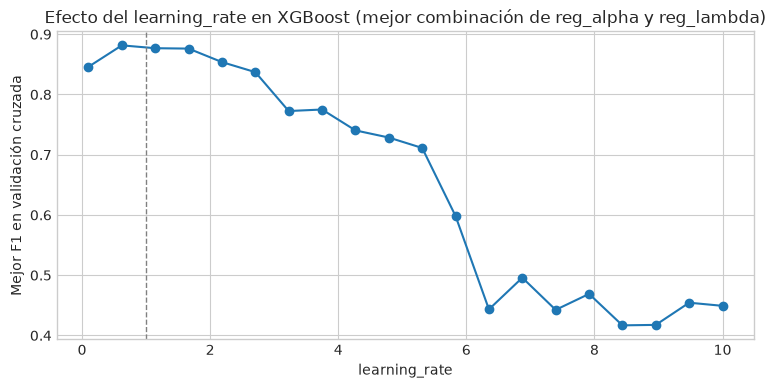

param_learning_rate
0.100000     0.846
0.621053     0.882
1.142105     0.877
1.663158     0.876
2.184211     0.854
2.705263     0.837
3.226316     0.773
3.747368     0.775
4.268421     0.740
4.789474     0.729
5.310526     0.711
5.831579     0.598
6.352632     0.443
6.873684     0.496
7.394737     0.442
7.915789     0.469
8.436842     0.417
8.957895     0.418
9.478947     0.454
10.000000    0.449
Name: mean_test_score, dtype: float64

Combinaciones empatadas con el mejor F1: 1


In [15]:
resultados_xgb = pd.DataFrame(xgb_grid.cv_results_)
f1_por_lr = resultados_xgb.groupby('param_learning_rate')['mean_test_score'].max()

plt.figure(figsize=(9, 4))
plt.plot(f1_por_lr.index, f1_por_lr.values, marker='o')
plt.axvline(1.0, color='gray', ls='--', lw=1)
plt.xlabel('learning_rate')
plt.ylabel('Mejor F1 en validación cruzada')
plt.title('Efecto del learning_rate en XGBoost (mejor combinación de reg_alpha y reg_lambda)')
plt.show()

print(f1_por_lr.round(3))
print('\nCombinaciones empatadas con el mejor F1:',
      (resultados_xgb['mean_test_score'] >= xgb_grid.best_score_ - 1e-9).sum())

**Observación efecto del learning_rate:** el F1 máximo se alcanza con learning_rate = 0.62 (≈0.88) y se mantiene en una meseta hasta ~1.7. Con 0.1 el desempeño es algo menor (≈0.85), porque con solo 100 árboles un paso tan corto no alcanza a converger. Por sobre ~2 el F1 cae de forma sostenida, y sobre ~6 colapsa (0.42–0.50): cada árbol corrige más de lo necesario, el modelo "salta" sobre el mínimo de la función de pérdida y no converge. Aun eligiendo la mejor combinación de reg_alpha y reg_lambda para cada tasa, la regularización no compensa un learning_rate excesivo. Valores de learning_rate mayores a 1 no son recomendables en la práctica.

In [16]:
xgb_opt = xgb_grid.best_estimator_

yhat_train_xgb = xgb_opt.predict(X_train_std)
yhat_test_xgb = xgb_opt.predict(X_test_std)

print('Métricas en train:')
print(classification_report(y_train, yhat_train_xgb, digits=3))
print('Métricas en test:')
print(classification_report(y_test, yhat_test_xgb, digits=3))

print('Matriz de confusión en test (filas = real, columnas = predicho):')
print(pd.DataFrame(confusion_matrix(y_test, yhat_test_xgb),
                   index=['Real 0 (sano)', 'Real 1 (condición)'],
                   columns=['Pred 0', 'Pred 1']))

Métricas en train:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       357
           1      1.000     1.000     1.000        53

    accuracy                          1.000       410
   macro avg      1.000     1.000     1.000       410
weighted avg      1.000     1.000     1.000       410

Métricas en test:
              precision    recall  f1-score   support

           0      0.983     0.994     0.989       176
           1      0.958     0.885     0.920        26

    accuracy                          0.980       202
   macro avg      0.971     0.939     0.954       202
weighted avg      0.980     0.980     0.980       202

Matriz de confusión en test (filas = real, columnas = predicho):
                    Pred 0  Pred 1
Real 0 (sano)          175       1
Real 1 (condición)       3      23


**Observación métricas XGBoost:** en test alcanza F1 de 0.920 en la clase 1 (precision 0.958, recall 0.885) y accuracy de 0.980. Detecta 23 de 26 pacientes con condición, reduciendo los falsos negativos de 10 (regresión logística) a 3, con el mismo único falso positivo. En entrenamiento clasifica perfectamente (1.000), lo que indica memorización y una brecha de 8 puntos en F1, pero a diferencia de otros casos esto no impide una buena generalización: las variables hepáticas presentan patrones de umbral marcados que los árboles capturan con facilidad.

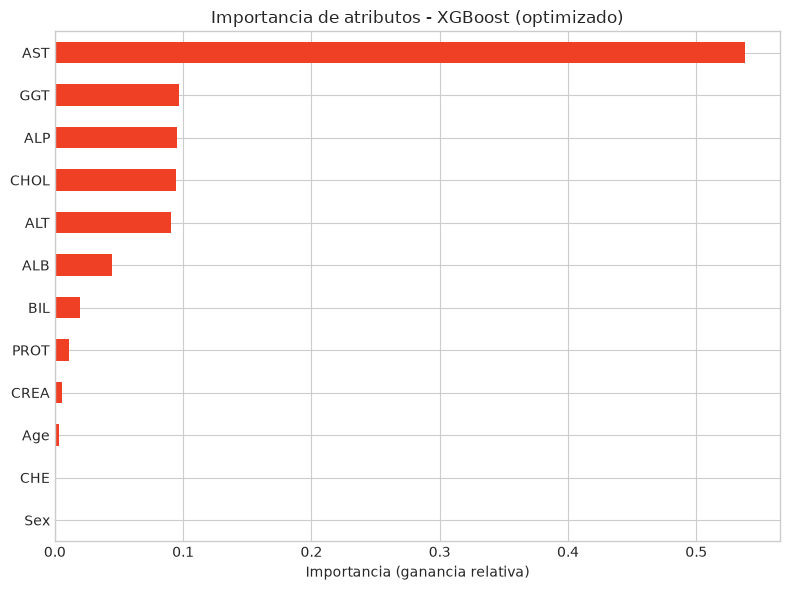

AST     0.538
GGT     0.097
ALP     0.095
CHOL    0.094
ALT     0.091
ALB     0.044
BIL     0.019
PROT    0.011
CREA    0.006
Age     0.003
CHE     0.001
Sex     0.000
dtype: float32


In [17]:
importancias_xgb = pd.Series(xgb_opt.feature_importances_, index=regresoras).sort_values()

plt.figure(figsize=(8, 6))
importancias_xgb.plot(kind='barh', color='xkcd:tomato')
plt.title('Importancia de atributos - XGBoost (optimizado)')
plt.xlabel('Importancia (ganancia relativa)')
plt.tight_layout()
plt.show()

print(importancias_xgb.sort_values(ascending=False).round(3))

### Importancia de atributos (XGBoost)

AST concentra más de la mitad de la importancia (≈0.54), seguida por un grupo parejo de GGT, ALP, CHOL y ALT (≈0.09–0.10 cada una). CHE y Sex no son utilizadas por el modelo.

Las tres variables más importantes (AST, GGT y ALP) son las mismas que en la regresión logística (GGT, ALP y AST), aunque en distinto orden, lo que refuerza su rol como principales marcadores. La diferencia más notable es ALT: con coeficiente prácticamente nulo en la regresión logística, en XGBoost es la quinta variable más importante. Su relación con la condición es no lineal (los enfermos presentan valores tanto bajos como muy altos), algo que los árboles capturan y un modelo lineal no.

**Verificación de fuga de información:** ALP y CHOL fueron imputadas por clase. Se revisaron los cortes del modelo sobre ALP: los cercanos al valor imputado (67.79) aportan solo ~2% de su ganancia, por lo que su importancia corresponde mayoritariamente a información genuina.

In [20]:
from sklearn.metrics import precision_score, recall_score, accuracy_score

def resumen(nombre, y_real, y_pred, f1_cv):
    return {
        'modelo': nombre,
        'accuracy': accuracy_score(y_real, y_pred),
        'precision_1': precision_score(y_real, y_pred),
        'recall_1': recall_score(y_real, y_pred),
        'f1_1': f1_score(y_real, y_pred),
        'f1_cv': f1_cv
    }

comparacion = pd.DataFrame([
    resumen('Regresión logística (Elastic Net)', y_test, yhat_test_en,
            logit_en.scores_.mean(axis=0).max()),
    resumen('XGBoost (optimizado)', y_test, yhat_test_xgb, xgb_grid.best_score_)
]).set_index('modelo').round(3)
comparacion

,accuracy,precision_1,recall_1,f1_1,f1_cv
modelo,,,,,
Regresión logística (Elastic Net),0.946,0.941,0.615,0.744,0.781
XGBoost (optimizado),0.980,0.958,0.885,0.920,0.882


**XGBoost supera a la regresión logística en todas las métricas.** La diferencia más importante está en el **recall de la clase 1**: XGBoost detecta 23 de 26 pacientes con condición (88.5%), frente a 16 de 26 (61.5%) de la regresión logística, reduciendo los falsos negativos de 10 a 3 con el mismo único falso positivo. En un contexto de tamizaje de donantes, donde no detectar a un paciente enfermo es el error más costoso, esta es la diferencia decisiva.

El accuracy de ambos modelos es alto (94.6% y 98.0%), pero en el caso de la regresión logística es engañoso: con 87% de donantes sanos, un modelo trivial obtendría 87.1%. El F1 y el recall de la clase 1 revelan la verdadera diferencia de desempeño.

La ventaja de XGBoost es consistente en validación cruzada (0.882 vs 0.781, sobre los mismos 5 folds), por lo que no depende de la partición de test. Se explica principalmente por la capacidad de los árboles para capturar relaciones no lineales y de umbral (AST muy elevado, ALT con valores extremos en ambas direcciones), que una frontera lineal no puede representar.

**Regularización:** en ambos modelos la búsqueda seleccionó una regularización suave. La regresión logística eligió Ridge puro (l1_ratio = 0, C = 3.32), conservando todas las variables y reduciendo sus coeficientes. XGBoost combinó un L1 leve (reg_alpha = 0.11) con un L2 cercano al valor por defecto (reg_lambda = 1.11), y un learning_rate moderado (0.62). La grilla de learning_rate mostró que valores mayores a ~2 degradan fuertemente el desempeño.

**Variables relevantes:** ambos modelos coinciden en que AST, GGT y ALP son los tres marcadores con mayor incidencia, lo que da solidez a esta conclusión.

**Modelo recomendado: XGBoost**, por su mayor capacidad para detectar pacientes con condición. Como contrapartida, la regresión logística es más interpretable (cada coeficiente tiene una lectura directa en términos de odds ratio) y más simple de comunicar.

## Conclusión final

Se construyeron dos modelos para identificar muestras de sangre con posible enfermedad hepática (hepatitis, fibrosis o cirrosis) en 612 donantes: una regresión logística con regularización Elastic Net y un modelo XGBoost con regularización L1 y L2, ambos optimizados por validación cruzada estratificada de 5 folds con F1 como métrica.

**Preparación de los datos.** Se eliminaron 3 pacientes con ausentes en variables con menos de 1% de faltantes y se imputaron ALP y CHOL por clase. La variable `suspect` se creó según lo solicitado, pero se excluyó de las regresoras por ser derivada de la variable objetivo (todos los sospechosos tienen target = 1). Los outliers, concentrados en pacientes enfermos, se conservaron por ser manifestaciones de la condición y no errores. La estandarización se ajustó solo con el conjunto de entrenamiento.

**Resultados.** XGBoost obtuvo F1 de 0.920 y recall de 0.885 en la clase 1, frente a 0.744 y 0.615 de la regresión logística, y se recomienda como modelo final. Los marcadores con mayor incidencia en ambos modelos son AST, GGT y ALP.

**Limitaciones.**
- **Desbalance y tamaño del test:** con solo 26 pacientes con condición en test, cada caso modifica el recall en ~4 puntos; las métricas deben interpretarse con cautela.
- **Imputación por clase:** usa la variable objetivo, lo que no es replicable con pacientes nuevos. Se verificó que su efecto en ALP es marginal (~2% de la ganancia de esa variable en XGBoost), pero en un uso real la imputación debería hacerse sin la variable objetivo.
- **Umbral de decisión:** ambos modelos usan el umbral por defecto (0.5). Para tamizaje clínico convendría evaluar umbrales menores o ponderar las clases (`class_weight` / `scale_pos_weight`) para aumentar el recall, a costa de más falsos positivos.
- **Grilla del learning_rate:** el rango solicitado (hasta 10) incluye valores no recomendables en la práctica; la mayor parte de la grilla corresponde a configuraciones que divergen.